In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
def f(x):
    return 3*x**2 +4*x + 5


In [3]:
f(2)

25

In [4]:
xs = np.arange(-10, 10, 0.25) 
xs


array([-10.  ,  -9.75,  -9.5 ,  -9.25,  -9.  ,  -8.75,  -8.5 ,  -8.25,
        -8.  ,  -7.75,  -7.5 ,  -7.25,  -7.  ,  -6.75,  -6.5 ,  -6.25,
        -6.  ,  -5.75,  -5.5 ,  -5.25,  -5.  ,  -4.75,  -4.5 ,  -4.25,
        -4.  ,  -3.75,  -3.5 ,  -3.25,  -3.  ,  -2.75,  -2.5 ,  -2.25,
        -2.  ,  -1.75,  -1.5 ,  -1.25,  -1.  ,  -0.75,  -0.5 ,  -0.25,
         0.  ,   0.25,   0.5 ,   0.75,   1.  ,   1.25,   1.5 ,   1.75,
         2.  ,   2.25,   2.5 ,   2.75,   3.  ,   3.25,   3.5 ,   3.75,
         4.  ,   4.25,   4.5 ,   4.75,   5.  ,   5.25,   5.5 ,   5.75,
         6.  ,   6.25,   6.5 ,   6.75,   7.  ,   7.25,   7.5 ,   7.75,
         8.  ,   8.25,   8.5 ,   8.75,   9.  ,   9.25,   9.5 ,   9.75])

In [5]:
ys = f(xs)
ys

array([265.    , 251.1875, 237.75  , 224.6875, 212.    , 199.6875,
       187.75  , 176.1875, 165.    , 154.1875, 143.75  , 133.6875,
       124.    , 114.6875, 105.75  ,  97.1875,  89.    ,  81.1875,
        73.75  ,  66.6875,  60.    ,  53.6875,  47.75  ,  42.1875,
        37.    ,  32.1875,  27.75  ,  23.6875,  20.    ,  16.6875,
        13.75  ,  11.1875,   9.    ,   7.1875,   5.75  ,   4.6875,
         4.    ,   3.6875,   3.75  ,   4.1875,   5.    ,   6.1875,
         7.75  ,   9.6875,  12.    ,  14.6875,  17.75  ,  21.1875,
        25.    ,  29.1875,  33.75  ,  38.6875,  44.    ,  49.6875,
        55.75  ,  62.1875,  69.    ,  76.1875,  83.75  ,  91.6875,
       100.    , 108.6875, 117.75  , 127.1875, 137.    , 147.1875,
       157.75  , 168.6875, 180.    , 191.6875, 203.75  , 216.1875,
       229.    , 242.1875, 255.75  , 269.6875, 284.    , 298.6875,
       313.75  , 329.1875])

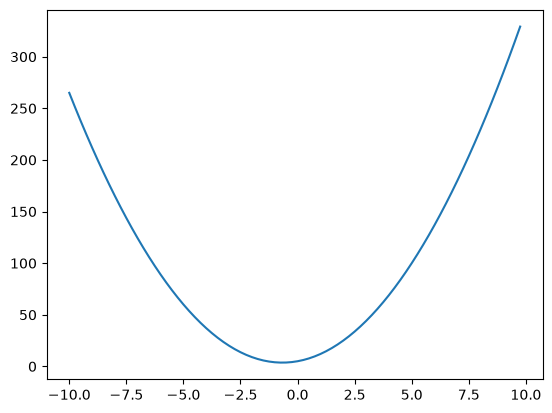

In [6]:
plt.plot(xs, ys)

In [7]:
h = 0.0001
x = 2
(f(x+h) - f(x)) / h


16.000300000058587

In [8]:
a = 2.0
b = -3.0
c = 10.0
d = a*b + c
d

4.0

In [9]:
h = 0.0001
a = 2.0
b = -3.0
c = 10.0
d1 = a*b + c
a += h
d2 = a*b + c
(d2 - d1) / h
print(d1, d2)
print((d2 - d1) / h)


4.0 3.999699999999999
-3.000000000010772


In [10]:
class Value:

    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        # self._children = _children
        self._op = _op
        self.label = label
       


    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, _children=(self, other), _op='+')
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, _children=(self, other), _op='*')
        return out
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = Value(t, _children=(self,), _op='tanh')
        return out
    
    def exp(self):
        out = Value(math.exp(self.data), _children=(self,), _op='exp')
        return out

    

In [11]:
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
print(a, b)
print(a.data, b.data)
print(type(a), type(b))
a+b
# (a.data __mul__ b.data). __add__(c.data)
# (a.__mul__(b)).__add__(c)
a*b + c

Value(data=2.0) Value(data=-3.0)
2.0 -3.0
<class '__main__.Value'> <class '__main__.Value'>


Value(data=4.0)

In [12]:
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b ;e.label = 'e'
d = e + c ;d.label = 'd'
f = Value(-2.0, label='f')
L = d*f ;L.label = 'L'

In [13]:
from graphviz import Digraph

def trace(out):
    """Build a set of all the children of this node, and their children, etc."""
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(out)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for simplicity, show data and not the grad here
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot 

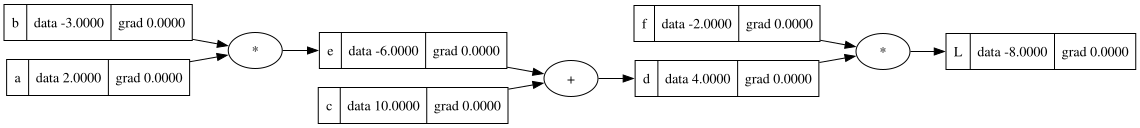

In [14]:
draw_dot(L)

# backpropegation


In [15]:
L.grad = 1.0

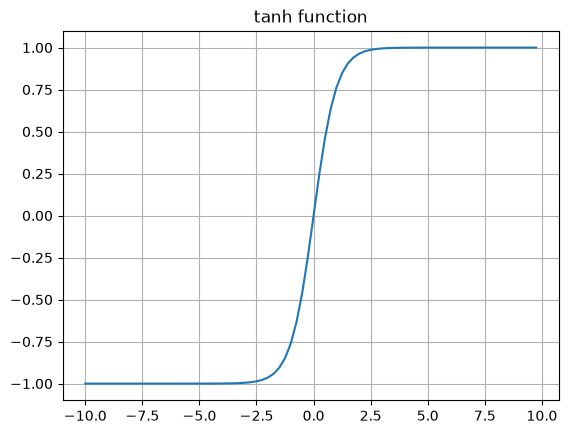

In [16]:
plt.plot(np.arange(-10, 10, 0.25), np.tanh(np.arange(-10, 10, 0.25))); plt.title('tanh function')   ;plt.grid()

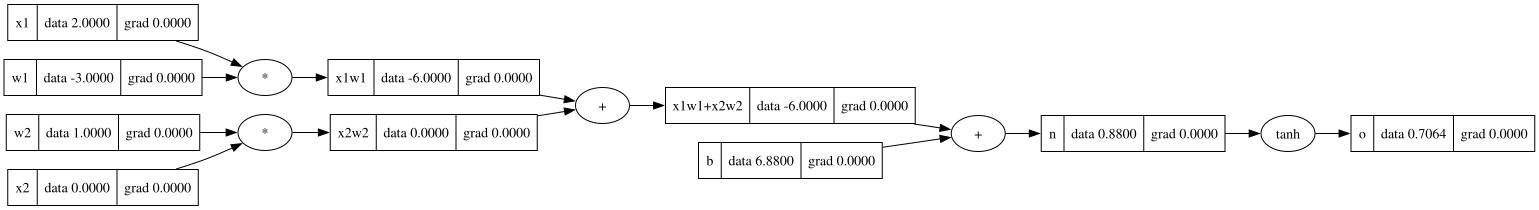

In [ ]:
# input x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias term
b=Value(6.88, label='b')  # bias term
x1w1=x1*w1 ; x1w1.label = 'x1w1'
x2w2=x2*w2 ; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1 + x2w2 ; x1w1x2w2.label = 'x1w1+x2w2'
n = x1w1x2w2 + b ; n.label = 'n'
o = n.tanh(); o.label = 'o'


In [25]:
o.grad = 1.0
n.grad = o.grad * (1 - o.data ** 2)
b.grad = n.grad
x1w1x2w2.grad = n.grad
x1w1.grad = x1w1x2w2.grad
x2w2.grad = x1w1x2w2.grad
x1.grad = x1w1.grad * w1.data
w1.grad = x1w1.grad * x1.data
x2.grad = x2w2.grad * w2.data
w2.grad = x2w2.grad * x2.data

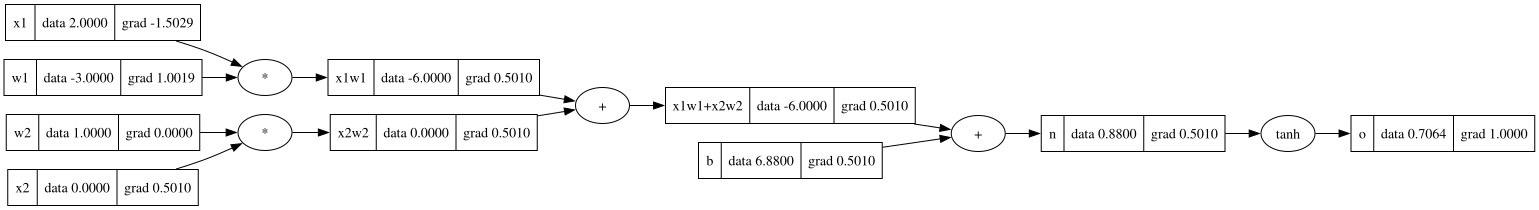

In [26]:

draw_dot(o)